# Study 1, notebook 3: background-only Lambda

Realisations with no source: the counts of every field are Poisson-faked from its background model,
and Lambda is computed exactly as on the data (same fields, same ROI). The distribution gives the
p-value of the data, and fixes the target Lambda* of the limit: Lambda_obs when the data are above
the background median, the background median otherwise.

Inputs: the case (parameter below), the reduced data from notebook 2 (cache `reduce`) and the
background realisations (cache `realisations_fields`, base seed `seed + flux_ul.SEED_STRIDE`). The
number of realisations is `flux_ul.DEFAULTS["n_bkg"]`; a larger sample goes through
`scripts/run_flux_ul.py`.

In [1]:
CASE = "sim_wobble"   # case name in configs/cases/

Imports, figure saver and the budget.

In [2]:
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")

import numpy as np
import matplotlib.pyplot as plt

from uuls import fields as fl, flux_ul, realisations, ulfit
from uuls.figures import FigureSaver, COLORS

figs = FigureSaver("1_flux_ul", "3_background")
N_BKG, SEED, N_JOBS = flux_ul.DEFAULTS["n_bkg"], flux_ul.DEFAULTS["seed"], 2

Fields (cached) and the observed Lambda.

In [3]:
prep = flux_ul.prepare(CASE)
flds, inj = prep["fields"], prep["injector"]
obs = fl.observed_lambda(flds)
print(f"{len(flds)} field(s), Lambda_obs = {obs['lambda']:.3f}")

[cache] gwmap/7a469d1cf166: loaded


1 field(s), Lambda_obs = -5.456


Background-only realisations (strength 0), all outputs kept. The first run takes several minutes; afterwards it is read from the cache.

In [4]:
bkg = realisations.run_fields(flds, inj, np.zeros(N_BKG), SEED + flux_ul.SEED_STRIDE, n_jobs=N_JOBS)
lam_bkg = bkg["lambda"]
print(f"{lam_bkg.size} realisations: median {np.median(lam_bkg):.3f}, "
      f"16-84% [{np.percentile(lam_bkg, 16):.3f}, {np.percentile(lam_bkg, 84):.3f}]")

[cache] realisations_fields/923496b479ca: loaded
1000 realisations: median -4.091, 16-84% [-6.045, -1.529]


p-value of the data, p = P(Lambda_bkg > Lambda_obs), its binomial error, the equivalent one-sided
significance, and the target Lambda* used by the limit.

In [5]:
target, p, s = ulfit.target_lambda(obs["lambda"], lam_bkg)
p_err = np.sqrt(max(p * (1 - p), 1 / lam_bkg.size) / lam_bkg.size)
print(f"p = {p:.3f} +- {p_err:.3f}, S = {s:.2f} sigma")
print(f"target Lambda* = {target:.3f} ({'Lambda_obs' if s >= 0 else 'background median'})")

p = 0.727 +- 0.014, S = -0.60 sigma
target Lambda* = -4.091 (background median)


The distribution and its survival function, with the data.

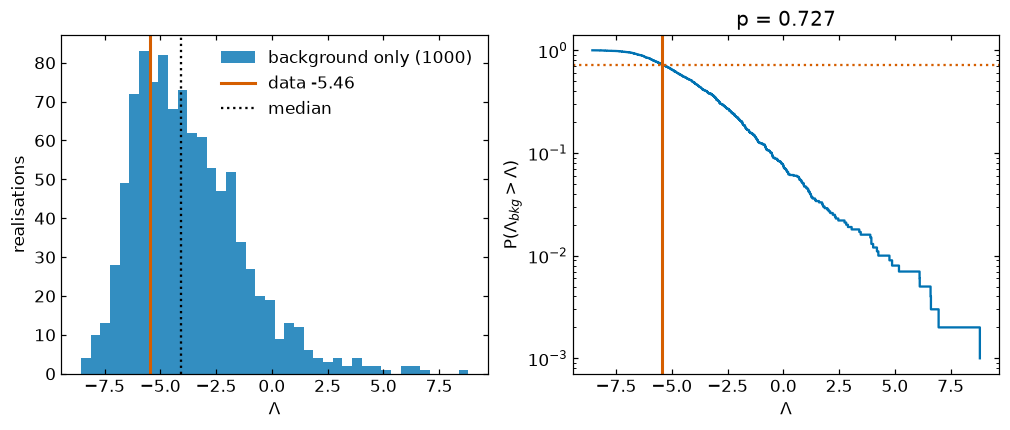

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].hist(lam_bkg, bins=40, color=COLORS[0], alpha=0.8, label=f"background only ({lam_bkg.size})")
axs[0].axvline(obs["lambda"], color=COLORS[3], lw=2, label=f"data {obs['lambda']:.2f}")
axs[0].axvline(np.median(lam_bkg), color="k", ls=":", label="median")
axs[0].set_xlabel(r"$\Lambda$")
axs[0].set_ylabel("realisations")
axs[0].legend()
x = np.sort(lam_bkg)
sf = 1.0 - np.arange(x.size) / x.size
axs[1].step(x, sf, where="post")
axs[1].axvline(obs["lambda"], color=COLORS[3], lw=2)
axs[1].axhline(max(p, 0.5 / x.size), color=COLORS[3], ls=":")
axs[1].set_yscale("log")
axs[1].set_xlabel(r"$\Lambda$")
axs[1].set_ylabel(r"P($\Lambda_{bkg} > \Lambda$)")
axs[1].set_title(f"p = {p:.3f}")
figs.save(fig, "lambda_background")
plt.show()

With several fields, the field that holds the background maximum. Fields with more GW probability in
their ROI win more often, through the 2 ln p term.

In [7]:
if len(flds) > 1:
    counts = np.bincount(bkg["lambda_field"], minlength=len(flds))
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.bar([f.name.replace("field", "") for f in flds], counts / counts.sum())
    ax.set_xlabel("field")
    ax.set_ylabel("fraction of realisations")
    ax.set_title("field holding the background maximum")
    figs.save(fig, "field_of_maximum")
    plt.show()
else:
    print("single field")

single field


## Outputs

Figures in `outputs/figures/1_flux_ul/3_background/`: `lambda_background` (and `field_of_maximum` with
several fields). The background sample is in `cache/realisations_fields`; notebook 4 reuses it.